# 已确认量额异常的局部信号影响

## tl;dr

替换33个有双源数值支持的量额字段，仅量价改变2个股票日期，超跌确认改变1个，其他六组直接入选信号未变。只是局部敏感性，非全库影响或收益复核。

## Context & Methods

冻结原参数与5224代码全覆盖排名，只替换20个存续对照中的33字段。原库与报告不修改。

### Key Assumptions

保留float32原实验计算口径；第三源不承诺独立上游。没有重算匹配分组、收益、容量或显著性，不能用此局部结果批准实盘。

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
root = Path.cwd().parents[1]
out = root / 'output/rps_input_impact_20261007/v1'
summary = json.loads((out/'summary.json').read_text(encoding='utf-8'))
patch = pd.read_csv(out/'patch_receipt.csv')
assert len(patch) == 33
assert patch.field.value_counts().to_dict() == {'amount':29, 'vol':4}
assert (patch.previous > 0).all() and (patch.replacement > 0).all()
print('Registered cells',len(patch))

Registered cells 33


## Data

changed_signals.csv保留所有翻转，model_sensitivity.csv保存八组汇总；不把同一股票日期重复计为独立样本。

In [2]:
events = pd.read_csv(out/'changed_signals.csv')
totals = pd.read_csv(out/'model_sensitivity.csv')
for row in totals.itertuples():
    assert row.changed == len(events.loc[events.model.eq(row.model)])
    assert row.added == len(events.loc[events.model.eq(row.model) & events.change.eq('added')])
    assert row.removed == len(events.loc[events.model.eq(row.model) & events.change.eq('removed')])
assert len(events[['signal_date','ts_code']].drop_duplicates()) == summary['changed_stock_dates'] == 3
display(events)

,model,signal_date,ts_code,change
0,pv_only,2025-12-02,000019.SZ,removed
1,pv_only,2025-12-15,000001.SZ,added
2,oversold_confirm,2025-11-28,000019.SZ,added


## Results

数字是股票×信号日入选变化，不是交易笔数或收益变化。价格和RPS描述符固定；成交量正值可用性也未改变。

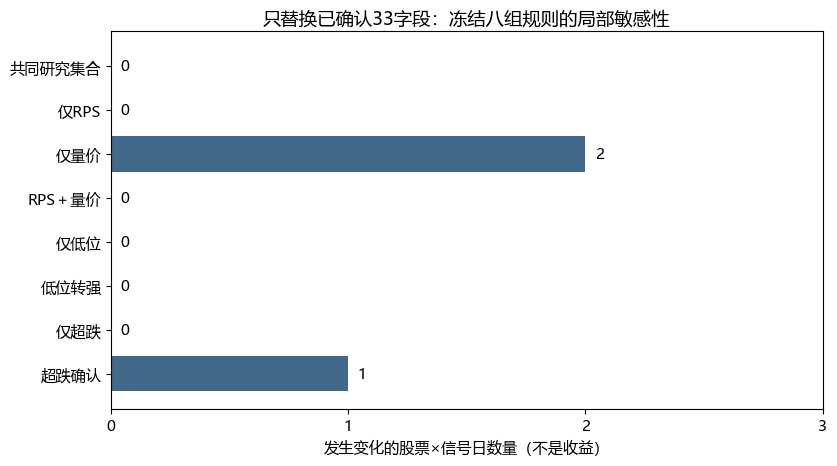

In [3]:
plt.rcParams.update({'font.family':'Microsoft YaHei','font.size':11})
fig, ax = plt.subplots(figsize=(8.5,4.8))
ax.barh(totals.label, totals.changed, color='#41698c')
ax.invert_yaxis()
ax.set_xlim(0,3)
ax.set_xticks([0,1,2,3])
ax.set_xlabel('发生变化的股票×信号日数量（不是收益）')
ax.set_title('只替换已确认33字段：冻结八组规则的局部敏感性')
for i,value in enumerate(totals.changed):
    ax.text(value+.04,i,str(value),va='center')
fig.tight_layout()
fig.savefig(out/'signal-impact.png',dpi=160)
plt.show()

## Takeaways

目前已确认量额异常不足以解释RPS＋量价全部历史失败，不能承诺修复就盈利。全库质量、匹配流动性分组和收益影响仍未测。直接信号只翻转3个股票日期，不能外推为整个供应商影响很小。